# Olist SQL Analysis: 8 Business Questions

SQL analysis of the Olist Brazilian e-commerce dataset (Kaggle), using SQLite inside Google Colab.
The 9 CSV files are loaded into a SQLite database, and every question is answered with SQL
(CTEs, window functions, views, conditional aggregation).

**Scope:** delivered orders purchased between Jan 2017 and Aug 2018 (months with complete data).

## 1. Load the data into SQLite

In [1]:
import os
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("images", exist_ok=True)

files = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

conn = sqlite3.connect("olist.db")
for table, path in files.items():
    pd.read_csv(path).to_sql(table, conn, if_exists="replace", index=False)

# indexes make the JOINs much faster
for ddl in [
    "CREATE INDEX IF NOT EXISTS idx_items_order ON order_items(order_id)",
    "CREATE INDEX IF NOT EXISTS idx_items_seller ON order_items(seller_id)",
    "CREATE INDEX IF NOT EXISTS idx_items_product ON order_items(product_id)",
    "CREATE INDEX IF NOT EXISTS idx_reviews_order ON reviews(order_id)",
    "CREATE INDEX IF NOT EXISTS idx_payments_order ON payments(order_id)",
    "CREATE INDEX IF NOT EXISTS idx_orders_customer ON orders(customer_id)",
]:
    conn.execute(ddl)
conn.commit()

def q(sql):
    return pd.read_sql(sql, conn)

q("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name")

,name
0,category_translation
1,customers
2,geolocation
3,order_items
4,orders
5,payments
6,products
7,reviews
8,sellers


In [2]:
q("""
SELECT 'orders' AS table_name, COUNT(*) AS n_rows FROM orders
UNION ALL SELECT 'order_items', COUNT(*) FROM order_items
UNION ALL SELECT 'customers', COUNT(*) FROM customers
UNION ALL SELECT 'reviews', COUNT(*) FROM reviews
UNION ALL SELECT 'payments', COUNT(*) FROM payments
UNION ALL SELECT 'sellers', COUNT(*) FROM sellers
""")

,table_name,n_rows
0,orders,99441
1,order_items,112650
2,customers,99441
3,reviews,99224
4,payments,103886
5,sellers,3095


## 2. Create views

Views keep the later queries short and make sure every question uses the same definitions:

- `order_reviews_avg`: one review score per order (some orders have several reviews)
- `delivered_orders`: delivered orders in the study period, one row per order, with delay in days
- `delivered_items`: the same orders, one row per item sold

In [3]:
conn.executescript("""
DROP VIEW IF EXISTS order_reviews_avg;
DROP VIEW IF EXISTS delivered_orders;
DROP VIEW IF EXISTS delivered_items;

CREATE VIEW order_reviews_avg AS
SELECT order_id, AVG(review_score) AS review_score
FROM reviews
GROUP BY order_id;

CREATE VIEW delivered_orders AS
SELECT o.order_id,
       o.customer_id,
       c.customer_unique_id,
       c.customer_state,
       strftime('%Y-%m', o.order_purchase_timestamp) AS month,
       CAST(julianday(o.order_delivered_customer_date)
            - julianday(o.order_estimated_delivery_date) AS INTEGER) AS delay_days,
       r.review_score
FROM orders o
JOIN customers c ON c.customer_id = o.customer_id
LEFT JOIN order_reviews_avg r ON r.order_id = o.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01';

CREATE VIEW delivered_items AS
SELECT oi.order_id, oi.order_item_id, oi.product_id, oi.seller_id,
       oi.price, oi.freight_value, d.month
FROM order_items oi
JOIN delivered_orders d ON d.order_id = oi.order_id;
""")
conn.commit()

# Sanity check: should match the Python/Looker Studio project (109,872 items, 96,203 orders)
q("""
SELECT COUNT(*) AS item_rows,
       COUNT(DISTINCT order_id) AS orders,
       ROUND(SUM(price), 2) AS revenue
FROM delivered_items
""")

,item_rows,orders,revenue
0,109872,96203,13179777.95


## Q1. Monthly revenue and month-over-month growth

*Techniques: CTE, `LAG` window function*

In [4]:
q1 = q("""
WITH monthly AS (
    SELECT month, ROUND(SUM(price), 2) AS revenue
    FROM delivered_items
    GROUP BY month
)
SELECT month,
       revenue,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY month))
             / LAG(revenue) OVER (ORDER BY month), 1) AS mom_growth_pct
FROM monthly
ORDER BY month
""")
q1

,month,revenue,mom_growth_pct
0,2017-01,111798.36,NaN
1,2017-02,234223.40,109.5
2,2017-03,359198.85,53.4
3,2017-04,340669.68,-5.2
4,2017-05,489159.25,43.6
5,2017-06,421923.37,-13.7
6,2017-07,481604.52,14.1
7,2017-08,554699.70,15.2
8,2017-09,607399.67,9.5
9,2017-10,648247.65,6.7


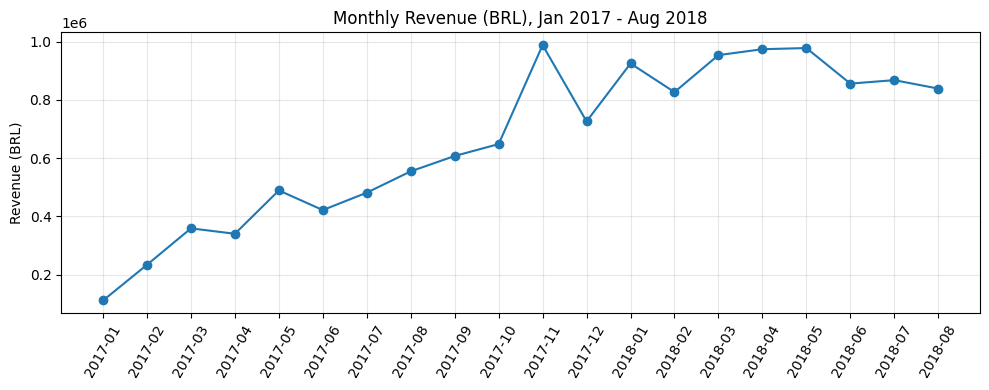

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(q1["month"], q1["revenue"], marker="o")
ax.set_title("Monthly Revenue (BRL), Jan 2017 - Aug 2018")
ax.set_ylabel("Revenue (BRL)")
ax.tick_params(axis="x", rotation=60)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("images/q1_monthly_revenue.png", dpi=150)
plt.show()

## Q2. Which categories drive revenue?

*Techniques: multi-table JOIN, `SUM() OVER` for share and cumulative share*

In [6]:
q2 = q("""
WITH cat AS (
    SELECT COALESCE(t.product_category_name_english, 'unknown') AS category,
           ROUND(SUM(di.price), 2) AS revenue
    FROM delivered_items di
    JOIN products p ON p.product_id = di.product_id
    LEFT JOIN category_translation t
           ON t.product_category_name = p.product_category_name
    GROUP BY category
)
SELECT category,
       revenue,
       ROUND(100.0 * revenue / SUM(revenue) OVER (), 1) AS share_pct,
       ROUND(100.0 * SUM(revenue) OVER (ORDER BY revenue DESC
             ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)
             / SUM(revenue) OVER (), 1) AS cumulative_share_pct
FROM cat
ORDER BY revenue DESC
LIMIT 10
""")
q2

,category,revenue,share_pct,cumulative_share_pct
0,health_beauty,1229557.50,9.3,9.3
1,watches_gifts,1163187.91,8.8,18.2
2,bed_bath_table,1022955.77,7.8,25.9
3,sports_leisure,952661.40,7.2,33.1
4,computers_accessories,887944.60,6.7,39.9
5,furniture_decor,706237.17,5.4,45.2
6,housewares,614341.62,4.7,49.9
7,cool_stuff,609158.00,4.6,54.5
8,auto,577721.09,4.4,58.9
9,garden_tools,469135.40,3.6,62.5


## Q3. Top 3 sellers by revenue in the five biggest seller states

*Techniques: CTEs, `RANK() OVER (PARTITION BY ...)`*

In [7]:
q3 = q("""
WITH seller_rev AS (
    SELECT s.seller_state,
           substr(s.seller_id, 1, 8) AS seller,
           ROUND(SUM(di.price), 2) AS revenue,
           COUNT(DISTINCT di.order_id) AS orders
    FROM delivered_items di
    JOIN sellers s ON s.seller_id = di.seller_id
    GROUP BY s.seller_state, s.seller_id
),
ranked AS (
    SELECT *,
           RANK() OVER (PARTITION BY seller_state ORDER BY revenue DESC) AS rank_in_state
    FROM seller_rev
)
SELECT seller_state, rank_in_state, seller, revenue, orders
FROM ranked
WHERE rank_in_state <= 3
  AND seller_state IN ('SP', 'RJ', 'MG', 'PR', 'SC')
ORDER BY seller_state, rank_in_state
""")
q3

,seller_state,rank_in_state,seller,revenue,orders
0,MG,1,a1043baf,99309.23,702
1,MG,2,25c5c91f,54208.78,156
2,MG,3,7299e27e,34107.44,335
3,PR,1,ccc4bbb5,72926.72,184
4,PR,2,522620dc,55981.69,169
5,PR,3,77530e97,45528.60,311
6,RJ,1,46dc3b2c,120566.48,494
7,RJ,2,620c87c1,107573.90,699
8,RJ,3,edb1ef5e,79144.90,165
9,SC,1,04308b1e,58991.80,92


## Q4. Which states have the most late deliveries, and how do they review?

*Techniques: view, conditional aggregation (`CASE`), `HAVING`*

Late = delivered at least one full day after the estimated delivery date. Only states with 500+ orders are shown.

In [8]:
q4 = q("""
SELECT customer_state,
       COUNT(*) AS orders,
       ROUND(100.0 * AVG(CASE WHEN delay_days > 0 THEN 1 ELSE 0 END), 1) AS late_pct,
       ROUND(AVG(review_score), 2) AS avg_review
FROM delivered_orders
GROUP BY customer_state
HAVING COUNT(*) >= 500
ORDER BY late_pct DESC
LIMIT 10
""")
q4

,customer_state,orders,late_pct,avg_review
0,MA,713,17.5,3.83
1,CE,1273,13.8,3.94
2,BA,3253,12.2,3.93
3,RJ,12310,12.1,3.97
4,PA,942,11.3,3.91
5,ES,1992,10.7,4.08
6,PB,516,10.5,4.07
7,MS,701,9.7,4.16
8,PE,1587,9.6,4.08
9,SC,3537,8.2,4.13


## Q5. How much does lateness hurt reviews?

*Techniques: `CASE` buckets, `GROUP BY`*

In [9]:
q5 = q("""
SELECT CASE
           WHEN delay_days <= 0 THEN '1. On time or early'
           WHEN delay_days <= 3 THEN '2. Late 1-3 days'
           WHEN delay_days <= 7 THEN '3. Late 4-7 days'
           ELSE '4. Late 8+ days'
       END AS delivery_bucket,
       COUNT(*) AS orders,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_orders,
       ROUND(AVG(review_score), 2) AS avg_review
FROM delivered_orders
WHERE review_score IS NOT NULL
GROUP BY delivery_bucket
ORDER BY delivery_bucket
""")
q5

,delivery_bucket,orders,pct_of_orders,avg_review
0,1. On time or early,89182,93.3,4.29
1,2. Late 1-3 days,1851,1.9,3.29
2,3. Late 4-7 days,1748,1.8,2.11
3,4. Late 8+ days,2779,2.9,1.70


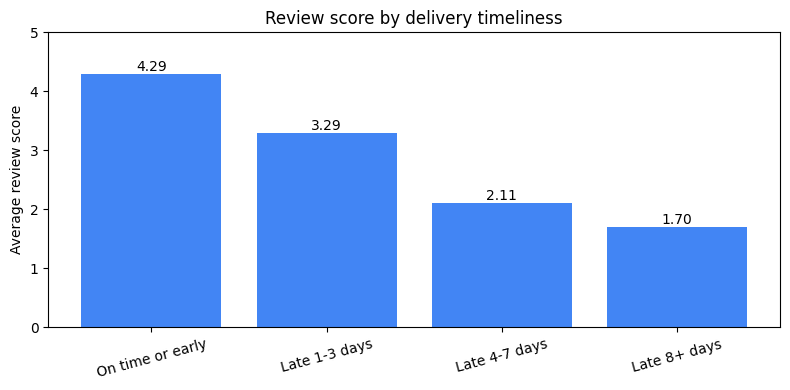

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(q5["delivery_bucket"].str[3:], q5["avg_review"], color="#4285f4")
for i, v in enumerate(q5["avg_review"]):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center")
ax.set_ylim(0, 5)
ax.set_ylabel("Average review score")
ax.set_title("Review score by delivery timeliness")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("images/q5_review_by_delay.png", dpi=150)
plt.show()

## Q6. What share of customers buy more than once?

*Techniques: CTE, `GROUP BY` / `HAVING`, conditional aggregation*

A customer is identified by `customer_unique_id` (the same person gets a new `customer_id` for every order).

In [11]:
q6 = q("""
WITH per_customer AS (
    SELECT customer_unique_id, COUNT(DISTINCT order_id) AS n_orders
    FROM delivered_orders
    GROUP BY customer_unique_id
)
SELECT COUNT(*) AS customers,
       SUM(CASE WHEN n_orders > 1 THEN 1 ELSE 0 END) AS repeat_customers,
       ROUND(100.0 * SUM(CASE WHEN n_orders > 1 THEN 1 ELSE 0 END) / COUNT(*), 2) AS repeat_pct,
       MAX(n_orders) AS max_orders_by_one_customer
FROM per_customer
""")
q6

,customers,repeat_customers,repeat_pct,max_orders_by_one_customer
0,93096,2789,3.0,15


## Q7. Which payment methods dominate?

*Techniques: aggregation, scalar subquery*

An order can use several payment types, so the percentages can add up to slightly more than 100%.

In [12]:
q7 = q("""
SELECT payment_type,
       COUNT(DISTINCT order_id) AS orders,
       ROUND(100.0 * COUNT(DISTINCT order_id)
             / (SELECT COUNT(DISTINCT order_id) FROM payments), 1) AS pct_of_orders,
       ROUND(AVG(payment_installments), 2) AS avg_installments,
       ROUND(AVG(payment_value), 2) AS avg_payment_value
FROM payments
GROUP BY payment_type
ORDER BY orders DESC
""")
q7

,payment_type,orders,pct_of_orders,avg_installments,avg_payment_value
0,credit_card,76505,76.9,3.51,163.32
1,boleto,19784,19.9,1.00,145.03
2,voucher,3866,3.9,1.00,65.70
3,debit_card,1528,1.5,1.00,142.57
4,not_defined,3,0.0,1.00,0.00


## Q8. Cumulative revenue over time

*Techniques: CTE, running total with `SUM() OVER`*

In [13]:
q8 = q("""
WITH monthly AS (
    SELECT month, ROUND(SUM(price), 2) AS revenue
    FROM delivered_items
    GROUP BY month
)
SELECT month,
       revenue,
       ROUND(SUM(revenue) OVER (ORDER BY month
             ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW), 2) AS cumulative_revenue
FROM monthly
ORDER BY month
""")
q8

,month,revenue,cumulative_revenue
0,2017-01,111798.36,111798.36
1,2017-02,234223.40,346021.76
2,2017-03,359198.85,705220.61
3,2017-04,340669.68,1045890.29
4,2017-05,489159.25,1535049.54
5,2017-06,421923.37,1956972.91
6,2017-07,481604.52,2438577.43
7,2017-08,554699.70,2993277.13
8,2017-09,607399.67,3600676.80
9,2017-10,648247.65,4248924.45


## 3. Save the figures

In [14]:
import shutil
shutil.make_archive("images", "zip", "images")
from google.colab import files
files.download("images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>